# LCMI — examples

**Local Conditional Mutual Information** estimates spatially varying, nonlinear effects in two stages:
1. **Local dependence:** local conditional mutual information (`{x}_lws`).
2. **Spatially varying effects:** a varying-coefficient model `y = b0(s) + Σ bj(s)·gj(xj)`, which gives
   - signed effect surfaces (`{x}_esd`);
   - learned transforms `gj`.

Contents
1. Synthetic data: recovering known effects
2. King County house prices
3. Benchmark against GWR, MGWR, GeoShapley and XGeoML (optional, slow)

In [1]:
import os, sys, time, warnings
os.environ.setdefault("TQDM_DISABLE", "1")      # quiet progress bars of the benchmark packages
os.environ.setdefault("PYTHONWARNINGS", "ignore")  # quiet warnings from parallel workers
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import lcmi
except ImportError:          # running from a clone of the repository
    sys.path.insert(0, "..")
    import lcmi
from lcmi import CMI
print("lcmi", lcmi.__version__)

lcmi 0.1.0


## 1. Synthetic data

A 100 × 100 grid, with three predictors whose effects vary in space **and** are nonlinear:

`y = β1(s)·x1 + β2(s)·sin(πx2) + β3(s)·x3² + ε`

- β1 is a plane;
- β2 is a central bump;
- β3 is a cos·cos pattern.

In [2]:
def make_synthetic(grid=100, seed=42):
    rng = np.random.default_rng(seed)
    u1 = np.linspace(0, 1, grid)
    U, V = np.meshgrid(u1, u1)
    u, v = U.ravel(), V.ravel()
    b1 = 2.0 * (u + v)
    b2 = 3.0 * np.exp(-((u - .5) ** 2 + (v - .5) ** 2) / (2 * .2 ** 2))
    b3r = 2.0 * np.cos(2 * np.pi * u) * np.cos(2 * np.pi * v)
    b3 = 2.0 * (b3r - b3r.min()) / (b3r.max() - b3r.min())
    x1, x2, x3 = rng.normal(size=(3, u.size))
    y = b1 * x1 + b2 * np.sin(np.pi * x2) + b3 * x3 ** 2 + rng.normal(0, .5, u.size)
    return pd.DataFrame(dict(u=u, v=v, y=y, x1=x1, x2=x2, x3=x3, beta1=b1, beta2=b2, beta3=b3))

GRID = 100
syn = make_synthetic(GRID)
XS = ["x1", "x2", "x3"]
syn.head()

,u,v,y,x1,x2,x3,beta1,beta2,beta3
0,0.000000,0.0,4.996591,0.304717,0.176277,-1.658201,0.000000,0.005791,2.000000
1,0.010101,0.0,1.544237,-1.039984,0.899123,0.891207,0.020202,0.006562,1.997986
2,0.020202,0.0,-0.628764,0.750451,-1.472271,-0.058032,0.040404,0.007417,1.991953
3,0.030303,0.0,0.406072,0.940565,-0.285298,-0.599909,0.060606,0.008362,1.981924
4,0.040404,0.0,-0.151145,-1.951035,0.829153,-0.250818,0.080808,0.009403,1.967941


### Fit
One call runs both stages. `k` (KSG neighbours) and the stage-1 window are searched automatically.

In [3]:
t0 = time.perf_counter()
m_syn = CMI(syn, u="u", v="v", y="y", xlist=XS, verbose=False).fit()
t_syn = time.perf_counter() - t0
print(f"fit time: {t_syn:.1f}s")
m_syn.summary()

fit time: 12.7s

CMI Model Summary
  Variables : ['x1', 'x2', 'x3']
  n         : 10000
  R²        : 0.8368
  R² stage 2 (P-spline VC): 0.9695
  alpha     : [2.4972 2.1054 1.8537]
  k per var : {'x1': 12, 'x2': 4, 'x3': 8}
  BW per var: {'x1': 122, 'x2': 122, 'x3': 115}
  ridge λ   : 0.0001


In [4]:
m_syn.coef_table()          # spatially varying effects ({x}_esd): Y per 1 SD of g(x)

,mean,sd,min,q05,median,q95,max,share_positive
variable,,,,,,,,
x1,2.013950,0.829096,-0.212326,0.626051,2.031942,3.409254,4.013325,0.9984
x2,0.506766,0.533615,-0.248015,-0.000509,0.289765,1.696062,2.037392,0.9489
x3,1.409531,0.708096,-0.045131,0.211221,1.408871,2.605312,3.213469,0.9967


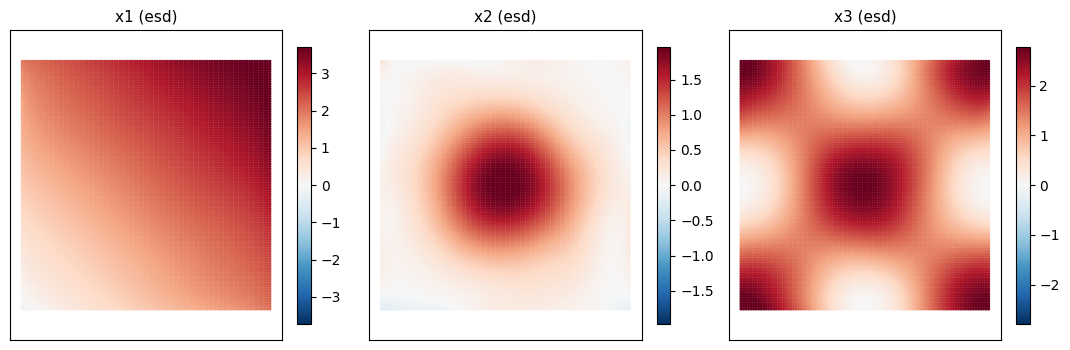

In [5]:
fig = m_syn.plot_coefficients()          # signed effect maps

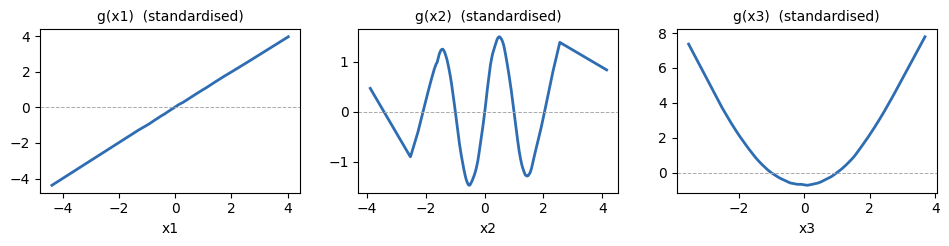

In [6]:
fig = m_syn.plot_transforms()            # learned shapes: linear, sine-like, U-shaped

### Compare with the truth
`{x}_esd` = b(s)·sd(g(x)). Its true counterpart is β(s)·sd(g_true(x)), so the two are on the same scale and can be compared 1:1.

,pearson,slope,rmse
variable,,,
x1,0.999,0.998,0.030
x2,0.997,0.982,0.044
x3,0.999,0.987,0.037


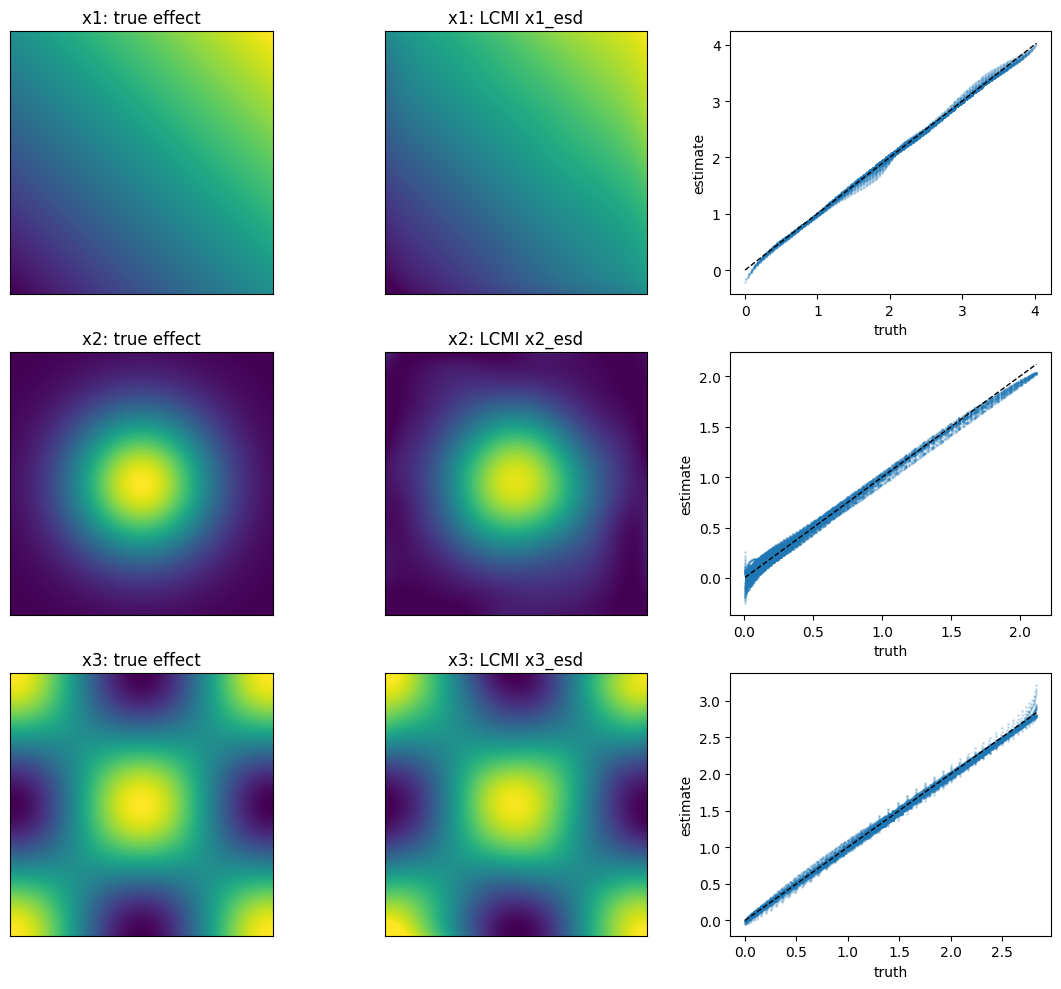

In [7]:
basis = {"x1": lambda x: x, "x2": lambda x: np.sin(np.pi * x), "x3": lambda x: x ** 2}
out = m_syn.df_out
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
rows = []
for r, x in enumerate(XS):
    truth = syn[f"beta{r+1}"].values * basis[x](syn[x].values).std()
    est = out[f"{x}_esd"].values
    lo, hi = truth.min(), truth.max()
    axes[r, 0].imshow(truth.reshape(GRID, GRID), origin="lower", vmin=lo, vmax=hi)
    axes[r, 0].set_title(f"{x}: true effect")
    axes[r, 1].imshow(est.reshape(GRID, GRID), origin="lower", vmin=lo, vmax=hi)
    axes[r, 1].set_title(f"{x}: LCMI {x}_esd")
    axes[r, 2].scatter(truth, est, s=1, alpha=.2)
    axes[r, 2].plot([lo, hi], [lo, hi], "k--", lw=1)
    axes[r, 2].set_xlabel("truth"); axes[r, 2].set_ylabel("estimate")
    for a in axes[r, :2]:
        a.set_xticks([]); a.set_yticks([])
    rows.append(dict(variable=x, pearson=np.corrcoef(truth, est)[0, 1],
                     slope=np.polyfit(truth, est, 1)[0],
                     rmse=np.sqrt(np.mean((truth - est) ** 2))))
plt.tight_layout()
pd.DataFrame(rows).set_index("variable").round(3)

Stage 1 also gives the local dependence strength (unsigned) and the partial-dependence decomposition:

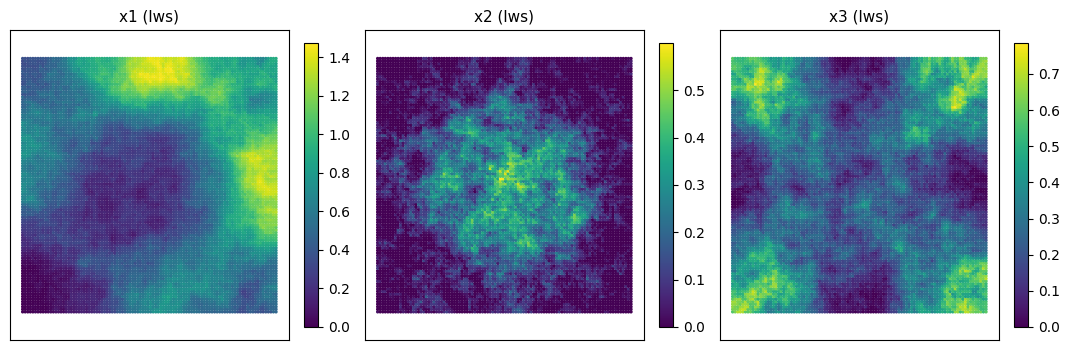

In [8]:
fig = m_syn.plot_coefficients(kind="lws")

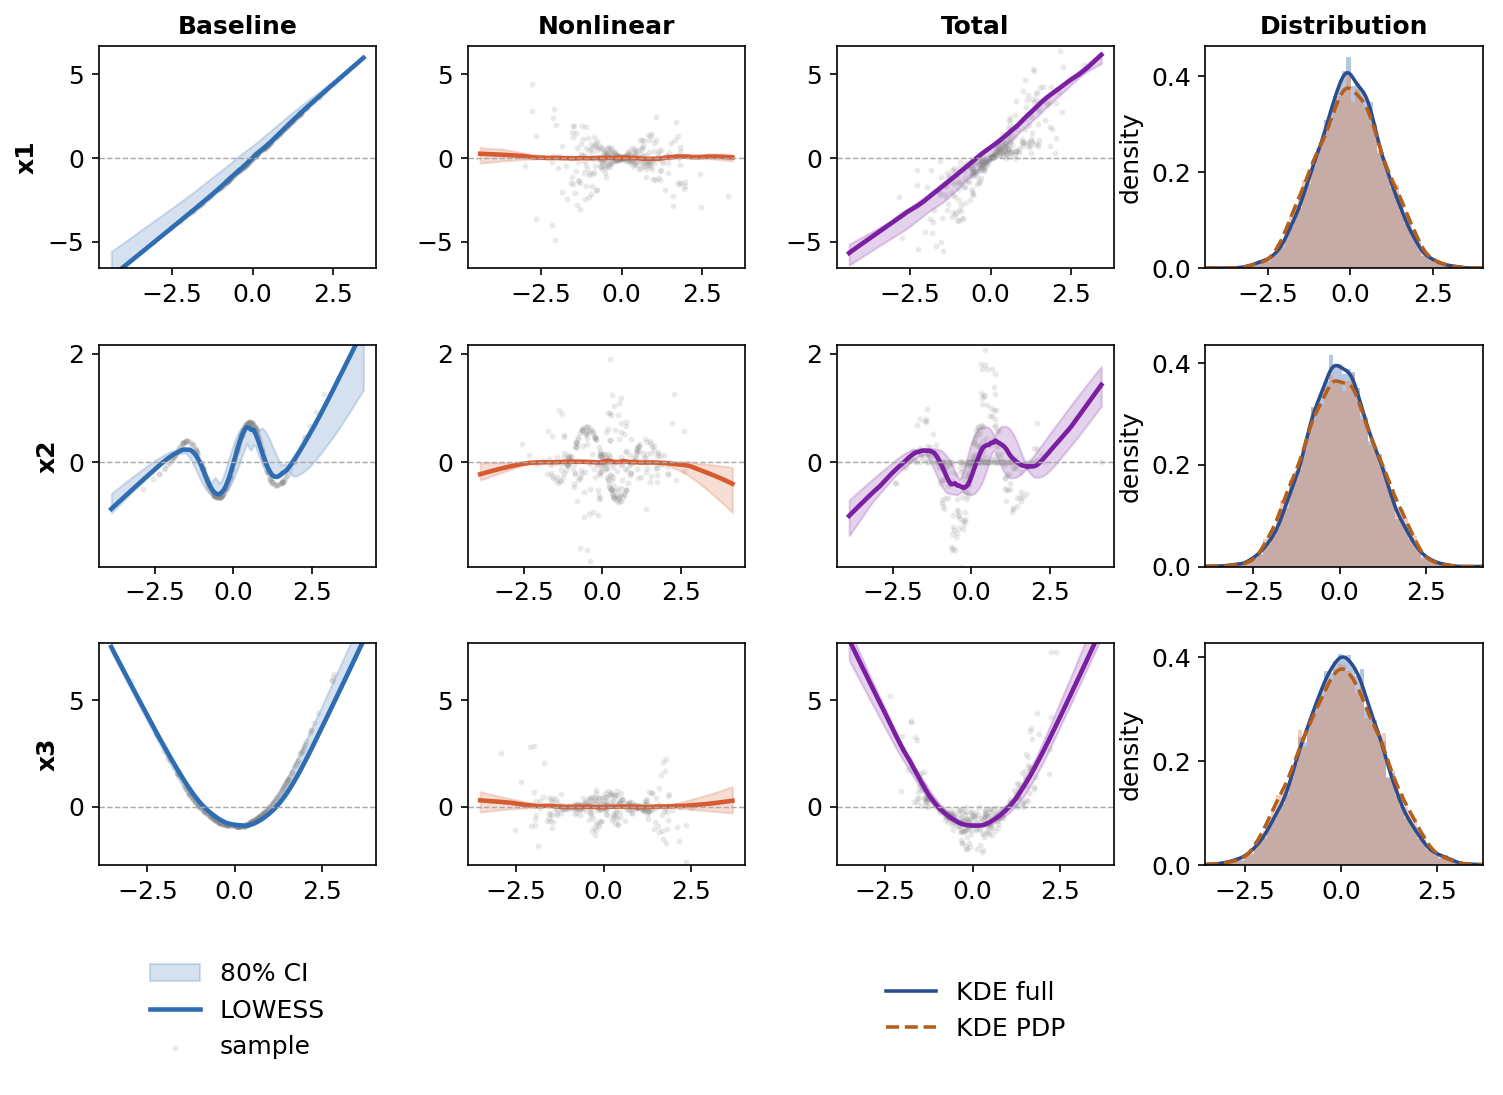

In [9]:
m_syn.plot_pdp(fast_mode=True, separated_legend=True)

## 2. King County house prices

House sales in King County, WA, 2015 ([GeoDa Center](https://geodacenter.github.io/data-and-lab/KingCounty-HouseSales2015/)). The CSV ships with the paper code in `lcmi-ijgis/data/`.

In [10]:
kc = pd.read_csv("../lcmi-ijgis/data/kc_house_data.csv")
kc = kc[(kc.price > 0) & (kc.bedrooms < 20) & (kc.sqft_living > 0) & (kc.long < -121.676)].copy()
kc["log_price"] = np.log(kc.price)
kc["log_sqft_living"] = np.log(kc.sqft_living)
kc["log_sqft_lot"] = np.log(kc.sqft_lot)
kc["age"] = 2015 - kc.yr_built
kc = kc.reset_index(drop=True)
KX = ["log_sqft_living", "log_sqft_lot", "grade", "waterfront", "view", "age"]
print(kc.shape)

(21593, 25)


In [11]:
t0 = time.perf_counter()
m_kc = CMI(kc, u="long", v="lat", y="log_price", xlist=KX,
           bw_candidates=[200, 250, 300, 350, 400, 450], verbose=False).fit()
print(f"fit time: {time.perf_counter() - t0:.1f}s")
m_kc.summary()
m_kc.coef_table()

fit time: 79.9s

CMI Model Summary
  Variables : ['log_sqft_living', 'log_sqft_lot', 'grade', 'waterfront', 'view', 'age']
  n         : 21593
  R²        : 0.7964
  R² stage 2 (P-spline VC): 0.8961
  alpha     : [ 0.6391 -0.0157  0.2706  0.1075  0.3612  0.0952]
  k per var : {'log_sqft_living': 12, 'log_sqft_lot': 4, 'grade': 6, 'waterfront': 4, 'view': 4, 'age': 4}
  BW per var: {'log_sqft_living': 314, 'log_sqft_lot': 386, 'grade': 450, 'waterfront': 482, 'view': 464, 'age': 400}
  ridge λ   : 0.0001


,mean,sd,min,q05,median,q95,max,share_positive
variable,,,,,,,,
log_sqft_living,0.190370,0.022316,-0.095224,0.159280,0.191184,0.225638,0.239729,0.999074
log_sqft_lot,0.043741,0.039221,-0.359278,-0.034353,0.051293,0.089581,0.124403,0.904645
grade,0.136222,0.030744,0.037250,0.087468,0.139095,0.187608,0.273546,1.000000
waterfront,0.045356,0.022452,0.002860,0.013503,0.042829,0.084099,0.133460,1.000000
view,0.039131,0.024402,-0.199178,0.005422,0.040152,0.075451,0.099741,0.957996
age,0.041849,0.033358,-0.158233,-0.012909,0.040091,0.104946,0.138867,0.916177


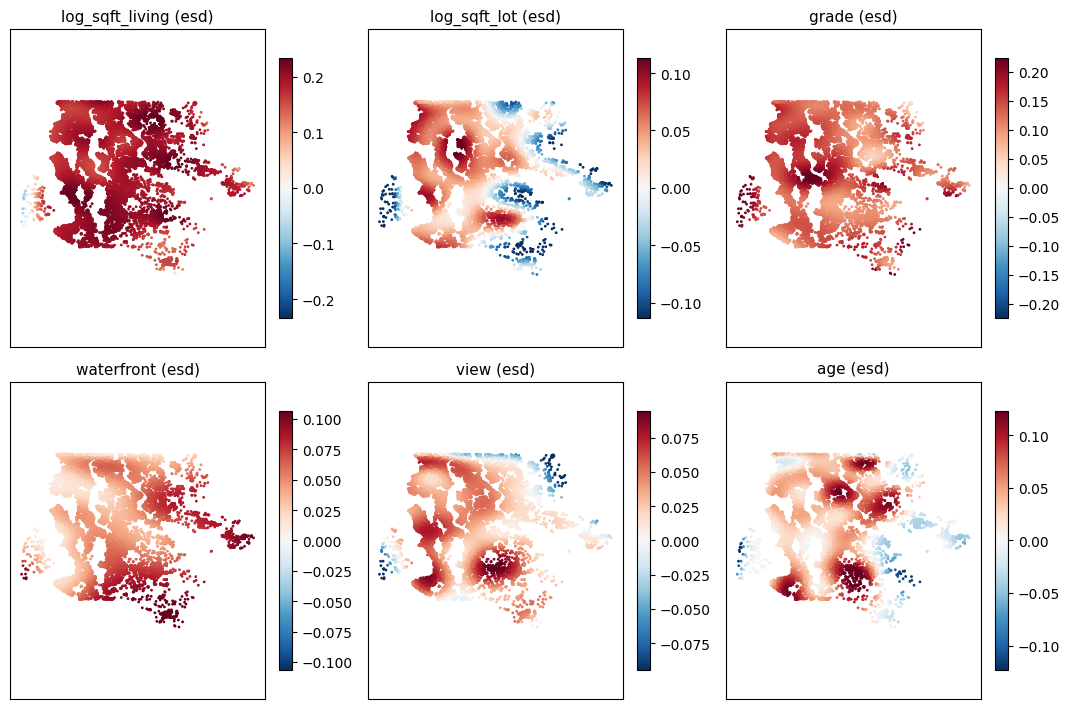

In [12]:
fig = m_kc.plot_coefficients(s=1)

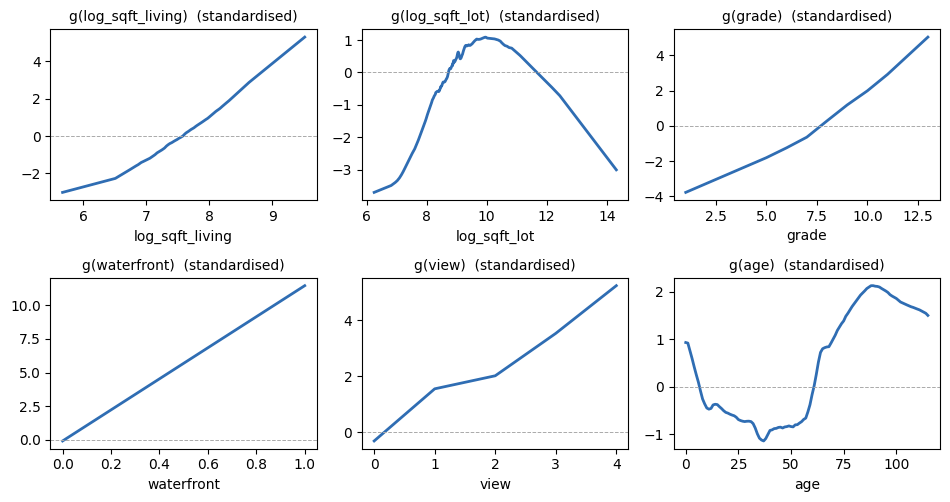

In [13]:
fig = m_kc.plot_transforms()

How to read a map: for example, `log_sqft_living_esd` = 0.20 at a location means that a one-SD increase in the learned transform of living area raises log price by about 0.20 there. Blue areas are where the effect runs against the orientation shown in `plot_transforms()`.

## 3. Benchmark: GWR, MGWR, GeoShapley, XGeoML (synthetic data)

Each method's coefficient surface is compared with the true β using
- Pearson r;
- Jaccard overlap of the top-25 % locations.

This is the same protocol as the paper.
- GWR and MGWR fit linear coefficients on raw x, so they cannot represent sin(πx) or x² effects.
- GeoShapley and XGeoML coefficients are derived from (local) SHAP values.

Needs `pip install mgwr geoshapley XGeoML`. On the 100 × 100 grid, **MGWR alone takes ~15 min**. Set `RUN_BENCHMARK = False` to skip, or lower `BENCH_GRID`.

In [14]:
RUN_BENCHMARK = True
BENCH_GRID = 100
bench = make_synthetic(BENCH_GRID) if BENCH_GRID != GRID else syn
coords = bench[["u", "v"]].to_numpy()
Xb, yb = bench[XS].to_numpy(), bench["y"].to_numpy()
truth = {x: bench[f"beta{j+1}"].to_numpy() for j, x in enumerate(XS)}
surfaces, r2, runtime = {}, {}, {}

In [15]:
if RUN_BENCHMARK:   # LCMI
    t0 = time.perf_counter()
    mb = m_syn if bench is syn else CMI(bench, u="u", v="v", y="y", xlist=XS, verbose=False).fit()
    runtime["LCMI"] = t_syn if bench is syn else time.perf_counter() - t0
    surfaces["LCMI"] = {x: mb.df_out[f"{x}_esd"].to_numpy() for x in XS}
    r2["LCMI"] = mb.result.meta["r2_vc"]

In [16]:
if RUN_BENCHMARK:   # GWR and MGWR
    from mgwr.gwr import GWR, MGWR
    from mgwr.sel_bw import Sel_BW
    Xs = (Xb - Xb.mean(0)) / Xb.std(0)
    ys = yb.reshape(-1, 1)
    t0 = time.perf_counter()
    bw = Sel_BW(coords, ys, Xs).search()
    gwr = GWR(coords, ys, Xs, bw).fit()
    runtime["GWR"] = time.perf_counter() - t0
    surfaces["GWR"] = {x: gwr.params[:, j + 1] for j, x in enumerate(XS)}
    r2["GWR"] = gwr.R2
    t0 = time.perf_counter()
    sel = Sel_BW(coords, ys, Xs, multi=True)
    sel.search()
    mgwr = MGWR(coords, ys, Xs, sel).fit()
    runtime["MGWR"] = time.perf_counter() - t0
    surfaces["MGWR"] = {x: mgwr.params[:, j + 1] for j, x in enumerate(XS)}
    r2["MGWR"] = mgwr.R2
    print(f"GWR bw={bw}, MGWR bws={sel.bw[0]}")

Backfitting:   0%|          | 0/200 [00:00<?, ?it/s]

Inference:   0%|          | 0/1 [00:00<?, ?it/s]

GWR bw=179.0, MGWR bws=[ 516. 1071. 4138.   43.]


In [17]:
if RUN_BENCHMARK:   # GeoShapley on a gradient-boosting model (as in the paper)
    from sklearn.ensemble import GradientBoostingRegressor
    from geoshapley import GeoShapleyExplainer
    Xg = bench[XS + ["u", "v"]]
    t0 = time.perf_counter()
    gbr = GradientBoostingRegressor(n_estimators=200, max_depth=5, random_state=42).fit(Xg.values, yb)
    bg = Xg.values[np.random.default_rng(53).choice(len(Xg), 150, replace=False)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gs = GeoShapleyExplainer(gbr.predict, bg).explain(Xg, n_jobs=-1)
        svc = gs.get_svc([0, 1, 2], coef_type="gwr", include_primary=True, coords=coords)
    runtime["GeoShapley"] = time.perf_counter() - t0
    surfaces["GeoShapley"] = {x: svc[:, j] for j, x in enumerate(XS)}
    r2["GeoShapley"] = gbr.score(Xg.values, yb)

  0%|          | 0/10000 [00:00<?, ?it/s]

In [18]:
if RUN_BENCHMARK:   # XGeoML: local gradient-boosting models + SHAP, GWR-smoothed (shap_gwr)
    from functools import partial
    from sklearn.ensemble import GradientBoostingRegressor
    from XGeoML import fast_train, w_matrix
    t0 = time.perf_counter()
    W = w_matrix.spatial_weight(bench, "u", "v", fix=False, bandwidth=300, kernel_type="Binary")
    local_model = partial(GradientBoostingRegressor, n_estimators=60, max_depth=3, random_state=0)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        xg = fast_train.explain(bench[["u", "v", "y"] + XS].copy(), XS, "y", W, local_model,
                                ["SHAP"], xcoord="u", ycoord="v", shap_gwr=True)
    runtime["XGeoML"] = time.perf_counter() - t0
    surfaces["XGeoML"] = {x: xg[f"{x}_SHAP_gwr"].to_numpy() for x in XS}
    r2["XGeoML"] = 1 - np.sum((yb - xg["predy"]) ** 2) / np.sum((yb - yb.mean()) ** 2)
    del W

In [19]:
if RUN_BENCHMARK:
    def jaccard_top(a, b, q=0.25):
        k = int(len(a) * q)
        A, B = set(np.argsort(a)[-k:]), set(np.argsort(b)[-k:])
        return len(A & B) / len(A | B)
    rows = []
    for name, surf in surfaces.items():
        for j, x in enumerate(XS):
            rows.append(dict(model=name, beta=f"β{j+1}", R2=r2[name], time_s=runtime.get(name),
                             pearson=np.corrcoef(truth[x], surf[x])[0, 1],
                             jaccard25=jaccard_top(truth[x], surf[x])))
    table = pd.DataFrame(rows)
    display(table.pivot(index="model", columns="beta", values="pearson").round(3)
            .join(table.groupby("model")[["R2", "time_s"]].first().round(3)))

,β1,β2,β3,R2,time_s
model,,,,,
GWR,0.979,0.283,0.182,0.660,13.783
GeoShapley,0.991,0.665,0.065,0.949,27.331
LCMI,0.999,0.997,0.999,0.970,12.724
MGWR,0.993,0.774,0.101,0.710,376.172
XGeoML,0.988,0.986,0.874,0.902,53.817


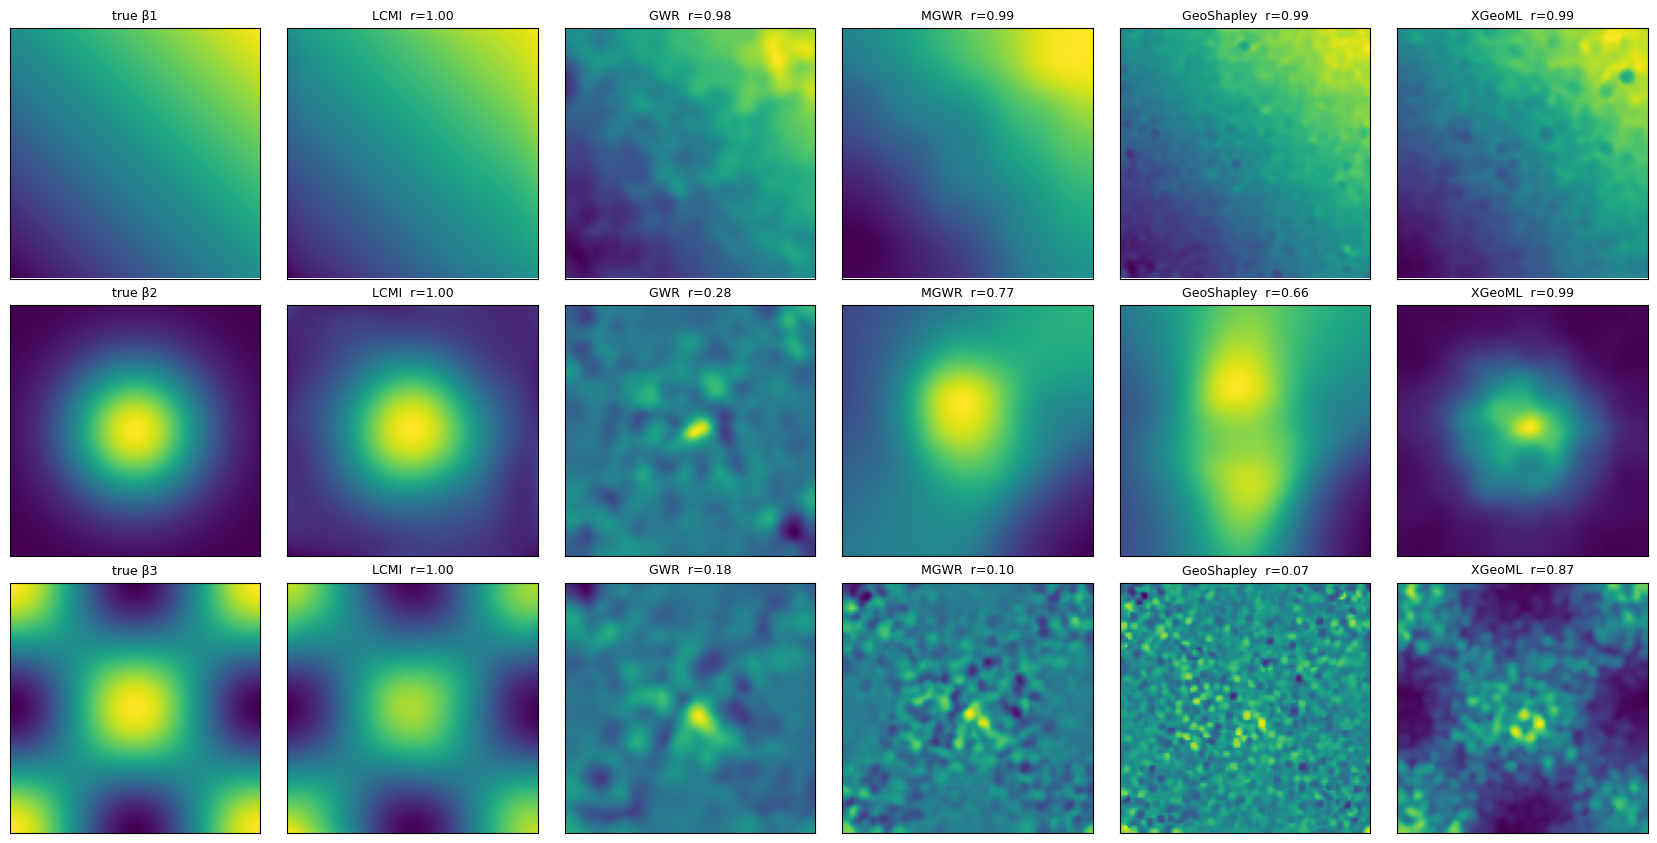

In [20]:
if RUN_BENCHMARK:
    names = list(surfaces)
    fig, axes = plt.subplots(3, len(names) + 1, figsize=(2.8 * (len(names) + 1), 8.5))
    for r, x in enumerate(XS):
        axes[r, 0].imshow(truth[x].reshape(BENCH_GRID, BENCH_GRID), origin="lower")
        axes[r, 0].set_title(f"true β{r+1}", fontsize=9)
        for c, name in enumerate(names, start=1):
            axes[r, c].imshow(surfaces[name][x].reshape(BENCH_GRID, BENCH_GRID), origin="lower")
            axes[r, c].set_title(f"{name}  r={np.corrcoef(truth[x], surfaces[name][x])[0,1]:.2f}", fontsize=9)
        for a in axes[r]:
            a.set_xticks([]); a.set_yticks([])
    plt.tight_layout()